# Trabajo Práctico 3: Clasificación de imágenes satelitales

Trabajamos con la versión RGB de EuroSAT para clasificar diez tipos de uso del suelo.
Primero entrenamos una CNN propia. Después analizamos sus errores y su representación
de las imágenes. Finalmente, comparamos ese modelo con VGG16 preentrenada en ImageNet.

## Replicable

Para replicar el trabajo, colocar la carpeta `EuroSAT` junto al notebook y ejecutar
las celdas en orden. La carpeta debe incluir las diez clases, `label_map.json` y los
CSV de entrenamiento, validación y test. Si está en otra ubicación, cambiar `DATA_DIR`.

Se necesitan PyTorch, torchvision, NumPy, Matplotlib y scikit-learn. La primera carga
de VGG16 descarga sus pesos de ImageNet si no están guardados en el equipo.
El entrenamiento completo puede tardar bastante en CPU.

Las conclusiones numéricas se generan con los resultados de cada ejecución.
Las pruebas de funcionamiento con pocos lotes no representan el rendimiento final.

Los gráficos, métricas, tablas y conclusiones se muestran en las salidas del notebook. Al guardar el `.ipynb`, esas salidas quedan incluidas. No se crean carpetas de resultados ni se exportan archivos adicionales. Los pesos de los modelos quedan en memoria durante la sesión; si se reinicia el kernel, hay que volver a entrenar antes de continuar con la evaluación.


In [1]:
import csv
import json
import random
import time
import copy
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms


In [2]:
#semilla
SEED = 22
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [3]:
#Dispositivo
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
print('Dispositivo:', device)


Dispositivo: cpu


In [4]:
#Directorios
DATA_DIR = Path('EuroSAT')


In [5]:
#Hiperparametros -> VER
BATCH_SIZE = 64
EPOCHS = 25
LR = 1e-3
GRAD_EPOCHS = 3
# En notebooks de Windows usamos 0 para evitar problemas de multiprocessing.
NUM_WORKERS = 0

## Carga de datos

Usamos las particiones incluidas en los CSV de EuroSAT. Entrenamiento se utiliza
para ajustar pesos, validación para seleccionar la mejor época y test para la
evaluación final. Conservamos las mismas particiones para ambos modelos.

La tabla siguiente permite revisar la cantidad de imágenes por clase.
Las particiones por archivo no permiten verificar independencia geográfica si no
contamos con las coordenadas de los recortes.

In [6]:
#Lectura JSON
with (DATA_DIR / 'label_map.json').open(encoding='utf-8') as f:
    class_to_idx = json.load(f)

# Ordenamos los nombres por su etiqueta numérica (0 a 9).
class_names = []
for label in range(10):
    for name in class_to_idx:
        if class_to_idx[name] == label:
            class_names.append(name)
assert len(class_names) == 10
num_classes = len(class_names)


In [7]:
# Adaptación a EuroSAT: los CSV ya indican qué imágenes van en cada partición.
# Solo leemos rutas y etiquetas; todavía no abrimos las imágenes.
def leer_split(nombre):
    muestras = []
    rutas_vistas = set()
    with (DATA_DIR / nombre).open(encoding='utf-8-sig', newline='') as f:
        reader = csv.DictReader(f)
        for row in reader:
            ruta = row['Filename'].replace('\\', '/')
            label = int(row['Label'])
            assert label == class_to_idx[row['ClassName']]
            assert (DATA_DIR / ruta).is_file(), ruta
            assert ruta not in rutas_vistas, 'Archivos repetidos'
            rutas_vistas.add(ruta)
            muestras.append((ruta, label))
    assert len(muestras) > 0
    return muestras


In [8]:
#Lectura de CSV's
train_samples = leer_split('train.csv')
val_samples = leer_split('validation.csv')
test_samples = leer_split('test.csv')

splits = {'train': train_samples, 'val': val_samples, 'test': test_samples}

In [9]:
print('Clase | Train | Val | Test')
for label in range(num_classes):
    counts = []
    for samples in [train_samples, val_samples, test_samples]:
        count = 0
        for ruta, image_label in samples:
            if image_label == label:
                count += 1
        assert count > 0
        counts.append(count)
    print(class_names[label], counts[0], counts[1], counts[2])

print('Totales:')
for name in splits:
    print(name, len(splits[name]))


Clase | Train | Val | Test
AnnualCrop 2100 600 300
Forest 2100 600 300
HerbaceousVegetation 2100 600 300
Highway 1750 500 250
Industrial 1750 500 250
Pasture 1400 400 200
PermanentCrop 1750 500 250
Residential 2100 600 300
River 1750 500 250
SeaLake 2100 600 300
Totales:
train 18900
val 5400
test 2700


## Preprocesamiento de datos

Las imágenes de la CNN propia se convierten a tensores con píxeles entre 0 y 1.
Durante el entrenamiento aplicamos reflejos y rotaciones en múltiplos de 90°.
Estos cambios de orientación suelen conservar el uso del suelo representado.

Validación y test conservan su orientación original. Las transformaciones se
aplican al cargar cada imagen, sin mantener el dataset completo en memoria.

In [10]:
#Data augmentation: Rotar ->VER
# DATA AUGMENTATION: adaptación de la rotación del taller a imágenes satelitales.
# Elegimos 0, 90, 180 o 270 grados; no cambiamos la clase del terreno.
# Una función alcanza: no necesitamos definir una clase de transformación.
def rotacion90(img):
    vueltas = random.randrange(4)
    return img.rotate(90 * vueltas)


In [11]:
#Transformación a tensores
# DATA AUGMENTATION: solo entrenamiento recibe reflejos y giros aleatorios.
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.Lambda(rotacion90),
    transforms.ToTensor(),
])

# PREPROCESAMIENTO: ToTensor convierte a tensor y escala los píxeles a [0, 1].
# Es el mismo escalado efectivo de la práctica 16: Normalize(0, 1) no lo cambia.
# En validación y test no generamos versiones aleatorias de las imágenes.
eval_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
])


In [12]:
# ImageFolder abre los archivos por demanda y asigna la clase según la carpeta.
train_full = datasets.ImageFolder(DATA_DIR, transform=train_transform)
eval_full = datasets.ImageFolder(DATA_DIR, transform=eval_transform)
assert train_full.class_to_idx == class_to_idx

# Adaptación a los CSV de EuroSAT: relacionamos cada ruta con su posición
# en ImageFolder, para conservar las particiones existentes con Subset.
indice_por_ruta = {}
for index in range(len(train_full.samples)):
    ruta, label = train_full.samples[index]
    ruta_relativa = Path(ruta).relative_to(DATA_DIR).as_posix()
    indice_por_ruta[ruta_relativa] = index

def obtener_indices(samples):
    indices = []
    for ruta, label in samples:
        index = indice_por_ruta[ruta]
        assert train_full.samples[index][1] == label
        indices.append(index)
    return indices


In [13]:
# Subset selecciona índices de un Dataset
train_indices = obtener_indices(train_samples)
val_indices = obtener_indices(val_samples)
test_indices = obtener_indices(test_samples)

train_dataset = Subset(train_full, train_indices)
val_dataset = Subset(eval_full, val_indices)
test_dataset = Subset(eval_full, test_indices)


In [14]:
# MINI-BATCHES: agrupamos imágenes; en entrenamiento mezclamos su orden.
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
)


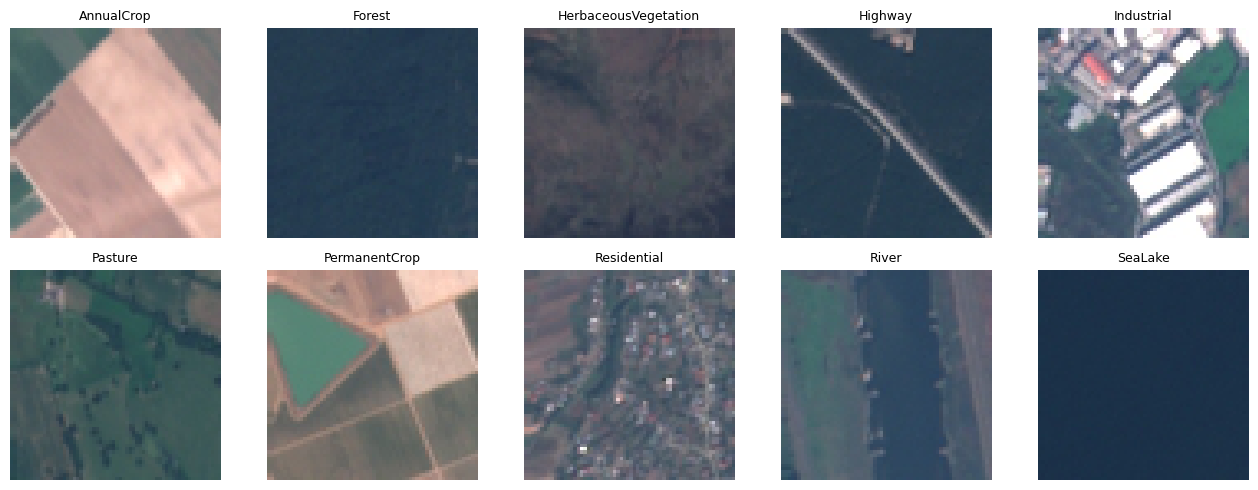

In [15]:
# Visualizamos una imagen por clase del conjunto de entrenamiento, sin aumentos.
preview_dataset = Subset(eval_full, train_indices)
fig, axes = plt.subplots(2, 5, figsize=(13, 5))
for label in range(num_classes):
    for index in range(len(train_samples)):
        ruta, image_label = train_samples[index]
        if image_label == label:
            img, _ = preview_dataset[index]
            break
    fila = label // 5
    columna = label % 5
    ax = axes[fila, columna]
    # ToTensor ya deja los píxeles en [0, 1]; no necesitamos desnormalizar.
    # Matplotlib espera (alto, ancho, canales), en vez de (canales, alto, ancho).
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(class_names[label], fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()


## 1. Arquitectura custom y entrenamiento desde cero
### CNN propia

La red sigue la estructura de la práctica 16: dos bloques convolucionales con
Leaky ReLU y max pooling, seguidos de dos capas densas. Adaptamos la entrada a
imágenes RGB de 64 × 64 y la salida a las diez clases de EuroSAT.

La capa densa intermedia genera un vector de 128 características. En el punto 2
vamos a analizar esa representación antes de la clasificación final.

In [16]:
# Conservamos una clase para la CNN:
# Permite registrar los pesos entrenables y definir explícitamente el forward.
class MiCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        # CONVOLUCIÓN
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16,
                               kernel_size=3, stride=1, padding=1)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32,
                               kernel_size=3, stride=1, padding=1)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # CAPAS DENSAS: 64x64 -> 32x32 -> 16x16 después de los dos poolings.
        self.fc1 = nn.Linear(32 * 16 * 16, 128)
        self.fc2 = nn.Linear(128, num_classes)

        # INICIALIZACIÓN: usamos la automática de PyTorch    

    def forward_features(self, x):
        # FORWARD PROPAGATION: bloque convolucional 1.
        x = self.conv1(x)
        # ACTIVACIÓN: Leaky ReLU
        x = F.leaky_relu(x)
        # POOLING: reduce a la mitad el alto y el ancho.
        x = self.pool1(x)

        # FORWARD PROPAGATION: bloque convolucional 2.
        x = self.conv2(x)
        x = F.leaky_relu(x)
        x = self.pool2(x)

        # FLATTEN: pasa de (lote, 32, 16, 16) a (lote, 8192).
        x = torch.flatten(x, 1)
        # REPRESENTACIÓN INTERMEDIA: vector de 128 características por imagen.
        # Separar este método permite extraerlas en el punto 2 del TP.
        x = self.fc1(x)
        x = F.leaky_relu(x)
        return x

    def forward(self, x):
        # FORWARD PROPAGATION COMPLETO: extracción seguida de clasificación.
        x = self.forward_features(x)
        # CLASIFICACIÓN: diez logits, uno por clase; todavía no son probabilidades.
        x = self.fc2(x)
        return x


In [17]:
model = MiCNN(num_classes).to(device)
print(model)
parametros_entrenables = 0
for parameter in model.parameters():
    if parameter.requires_grad:
        parametros_entrenables += parameter.numel()
print('Parámetros entrenables:', parametros_entrenables)


MiCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=8192, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Parámetros entrenables: 1055082


### Entrenamiento y flujo de gradientes

Entrenamos con CrossEntropyLoss y Adam. Registramos pérdida y accuracy en
entrenamiento y validación, y conservamos los pesos de la época con menor pérdida
de validación.

Durante las primeras épocas medimos la magnitud de los gradientes por capa.
Esto permite buscar indicios de desvanecimiento o explosión junto con las curvas
de aprendizaje. Un valor aislado no alcanza para confirmar esos problemas.

In [18]:
# FUNCIÓN DE PÉRDIDA: clasificación multiclase
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

def entrenar_una_epoca(model, loader, criterion, optimizer, monitorear=False):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    grad_sumas = {}
    grad_maximos = {}
    cantidad_lotes = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        # LIMPIEZA: PyTorch acumula gradientes; borramos los del lote anterior.
        optimizer.zero_grad()
        # FORWARD PROPAGATION: obtenemos diez puntajes por imagen.
        logits = model(images)
        # LOSS FUNCTION: comparamos los puntajes con las etiquetas correctas.
        loss = criterion(logits, labels)
        # BACKPROPAGATION: calcula la derivada del error respecto de cada peso.
        loss.backward()

        # MONITOREO DE GRADIENTES: agregado necesario para el requisito del TP.
        # También verificamos valores no finitos fuera de las épocas monitoreadas.
        # La verificación anterior se reemplazó: ahora inspeccionamos solo al monitorear.
        if monitorear:
            for name, parameter in model.named_parameters():
                if parameter.grad is not None and parameter.ndim > 1:
                    # .grad contiene las derivadas calculadas por backward.
                    # detach evita registrar operaciones nuevas en el grafo.
                    gradiente = parameter.grad.detach()
                    if not torch.isfinite(gradiente).all().item():
                        raise RuntimeError('Gradiente no finito en ' + name)
                    # abs evita que positivos y negativos se cancelen al promediar.
                    media_absoluta = gradiente.abs().mean().item()
                    maximo_absoluto = gradiente.abs().max().item()
                    if name not in grad_sumas:
                        grad_sumas[name] = 0.0
                        grad_maximos[name] = 0.0
                    grad_sumas[name] += media_absoluta
                    if maximo_absoluto > grad_maximos[name]:
                        grad_maximos[name] = maximo_absoluto

        # ACTUALIZACIÓN DE PESOS: Adam usa los gradientes para ajustar la red.
        optimizer.step()

        # MÉTRICAS: ponderamos la pérdida por el tamaño real del lote.
        n = labels.size(0)
        total_loss += loss.item() * n
        _, predicted = torch.max(logits, 1)
        correct += (predicted == labels).sum().item()
        total += n
        cantidad_lotes += 1

    # Promedio de las medias absolutas por lote, para cada capa.
    grad_medias = {}
    for name in grad_sumas:
        grad_medias[name] = grad_sumas[name] / cantidad_lotes
    return total_loss / total, 100 * correct / total, grad_medias, grad_maximos

def evaluar(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    # EVALUACIÓN: solo forward; no calculamos gradientes ni actualizamos pesos.
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            loss = criterion(logits, labels)
            total_loss += loss.item() * labels.size(0)
            _, predicted = torch.max(logits, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, 100 * correct / total


In [ ]:
# Ejecutar esta celda inicia una corrida nueva desde cero.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
model = MiCNN(num_classes).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

history = {
    'train_loss': [],
    'val_loss': [],
    'train_acc': [],
    'val_acc': [],
    'seconds': [],
}
gradient_history = []
best_val_loss = float('inf')
best_epoch = 0
best_val_acc = 0.0

for epoch in range(1, EPOCHS + 1):
    inicio = time.time()
    # ENTRENAMIENTO: un recorrido por todos los lotes con actualización de pesos.
    train_loss, train_acc, grad_medias, grad_maximos = entrenar_una_epoca(
        model, train_loader, criterion, optimizer, monitorear=epoch <= GRAD_EPOCHS
    )
    # VALIDACIÓN: mide el rendimiento sin aprender de este conjunto.
    val_loss, val_acc = evaluar(model, val_loader, criterion)
    seconds = time.time() - inicio

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)
    history['seconds'].append(seconds)
    if epoch <= GRAD_EPOCHS:
        gradient_history.append({
            'epoch': epoch, 'medias': grad_medias, 'maximos': grad_maximos
        })
    print(f'Época {epoch}/{EPOCHS} | train loss {train_loss:.4f}, acc {train_acc:.2f}% '
          f'| val loss {val_loss:.4f}, acc {val_acc:.2f}% | {seconds:.1f} s')

    # Selección exclusivamente por validación, sin consultar test.
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_val_acc = val_acc
        best_epoch = epoch
        # Agregado: guardamos una copia de los pesos de la mejor época.
        # state_dict es el diccionario de parámetros; deepcopy evita que
        # las siguientes actualizaciones modifiquen esa copia.
        best_weights = copy.deepcopy(model.state_dict())

# Agregado: restauramos esa copia para usar el modelo elegido en el punto 2.
model.load_state_dict(best_weights)
model.eval()
# Agregado: persistimos pesos y métricas para no perderlos al cerrar el notebook.
# Nota: ese guardado se quitó; ahora los resultados se muestran en el notebook.

print(f'Mejor época: {best_epoch}, val loss: {best_val_loss:.4f}, '
      f'val accuracy: {best_val_acc:.2f}%')
print('Se restauraron los mejores pesos. Test queda para el punto 2.')


Época 1/25 | train loss 1.3259, acc 51.18% | val loss 0.9359, acc 67.00% | 36.0 s


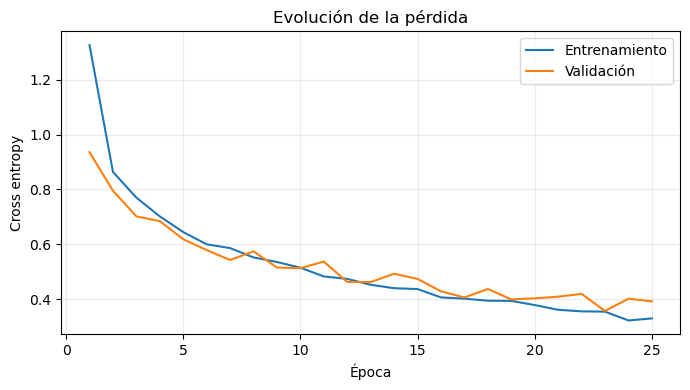

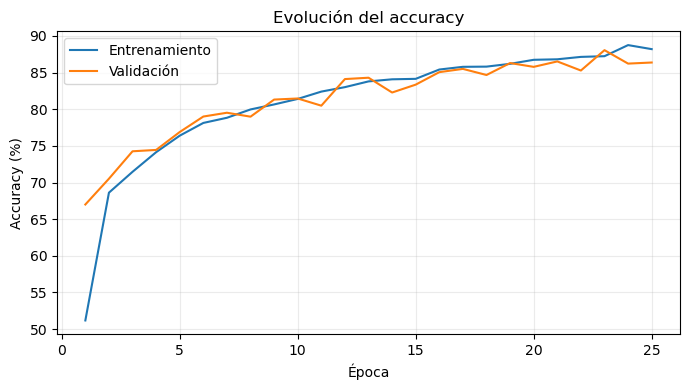

In [ ]:
# CURVAS DE APRENDIZAJE: pérdida y accuracy en entrenamiento y validación.
epochs = range(1, len(history['train_loss']) + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs, history['train_loss'], label='Entrenamiento')
plt.plot(epochs, history['val_loss'], label='Validación')
plt.xlabel('Época')
plt.ylabel('Cross entropy')
plt.title('Evolución de la pérdida')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(epochs, history['train_acc'], label='Entrenamiento')
plt.plot(epochs, history['val_acc'], label='Validación')
plt.xlabel('Época')
plt.ylabel('Accuracy (%)')
plt.title('Evolución del accuracy')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


Época 1 | conv1.weight | media |grad|: 0.2793022792198777 | máximo |grad|: 9.796395301818848
Época 1 | conv2.weight | media |grad|: 0.036918179311386835 | máximo |grad|: 2.2142715454101562
Época 1 | fc1.weight | media |grad|: 0.00018600454879216723 | máximo |grad|: 0.015094324946403503
Época 1 | fc2.weight | media |grad|: 0.036093004819908736 | máximo |grad|: 1.9207655191421509
Época 2 | conv1.weight | media |grad|: 0.4939746650539943 | máximo |grad|: 11.543697357177734
Época 2 | conv2.weight | media |grad|: 0.03981675040228544 | máximo |grad|: 1.5939950942993164
Época 2 | fc1.weight | media |grad|: 0.0001843818681909643 | máximo |grad|: 0.011982616037130356
Época 2 | fc2.weight | media |grad|: 0.04294068484592277 | máximo |grad|: 1.2117873430252075
Época 3 | conv1.weight | media |grad|: 0.5722746244455511 | máximo |grad|: 14.708528518676758
Época 3 | conv2.weight | media |grad|: 0.03756696058474984 | máximo |grad|: 1.626495361328125
Época 3 | fc1.weight | media |grad|: 0.0001763145432

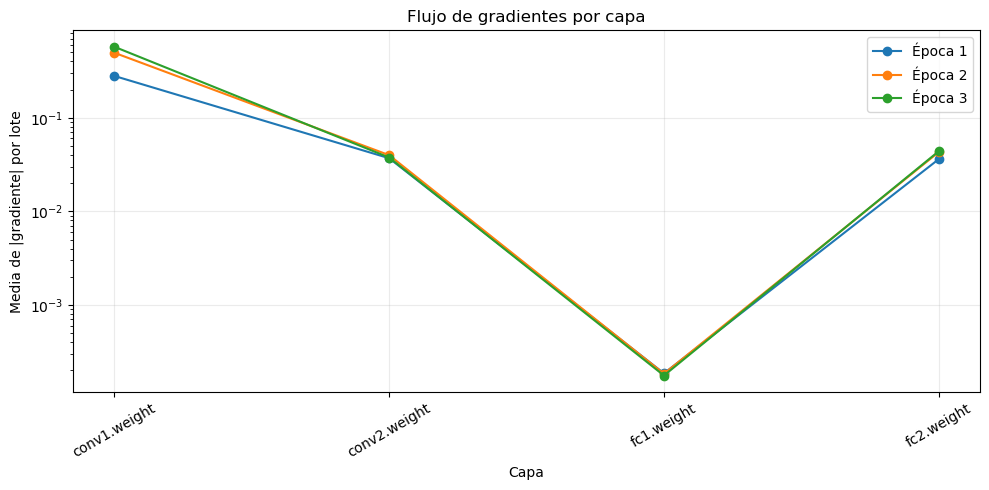

In [ ]:
# MONITOREO DEL FLUJO DE GRADIENTES: medias por capa en las primeras épocas.
plt.figure(figsize=(10, 5))
for record in gradient_history:
    names = []
    values = []
    for name in record['medias']:
        names.append(name)
        value = record['medias'][name]
        # Piso solo para dibujar en escala logarítmica; se conservan ceros en el historial.
        # log(0) no existe: el piso no modifica los gradientes del entrenamiento.
        values.append(max(value, 1e-12))
        print('Época', record['epoch'], '|', name,
              '| media |grad|:', value, '| máximo |grad|:', record['maximos'][name])
    plt.plot(names, values, marker='o', label='Época ' + str(record['epoch']))

# La escala logarítmica permite comparar órdenes de magnitud entre capas.
plt.yscale('log')
plt.xlabel('Capa')
plt.ylabel('Media de |gradiente| por lote')
plt.title('Flujo de gradientes por capa')
plt.xticks(rotation=30)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


### Análisis del entrenamiento

Las curvas permiten revisar si el modelo aprende y si aparece sobreajuste.
Una mejora sostenida en entrenamiento acompañada por un deterioro de validación
sería un indicio de sobreajuste. Train incluye aumentos aleatorios y validación no,
por lo que las condiciones de ambas métricas no son exactamente iguales.

La selección de la época usa únicamente validación. Los gradientes se interpretan
junto con las curvas: valores persistentemente cercanos a cero pueden acompañar
falta de aprendizaje, y máximos crecientes pueden acompañar inestabilidad.

## 2. Análisis de errores y espacio latente
### Evaluación en test

Evaluamos la CNN con los pesos seleccionados en el punto 1. Reportamos accuracy,
precision, recall y F1 por clase, además de F1-macro para dar el mismo peso a cada
clase. El conjunto de test se utiliza para describir el rendimiento final, sin
ajustar hiperparámetros a partir de sus resultados.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.decomposition import PCA
from IPython.display import display, Markdown
from torchvision import models

cnn_custom = model  # Pesos elegidos por validación.
history_custom = copy.deepcopy(history)
best_epoch_custom = best_epoch
best_val_acc_custom = best_val_acc

def predecir(modelo, loader):
    modelo.eval()
    reales = []
    predichas = []
    with torch.no_grad():  # Solo forward propagation.
        for images, labels in loader:
            images = images.to(device)
            logits = modelo(images)
            _, predicted = torch.max(logits, 1)
            reales.extend(labels.tolist())
            predichas.extend(predicted.cpu().tolist())
    return np.array(reales), np.array(predichas)

y_test, pred_custom = predecir(cnn_custom, test_loader)
acc_custom = accuracy_score(y_test, pred_custom)
f1_custom = f1_score(y_test, pred_custom, average='macro', zero_division=0)
print('Accuracy test:', round(acc_custom, 4))
print('F1-macro test:', round(f1_custom, 4))
print(classification_report(y_test, pred_custom, labels=range(num_classes),
                            target_names=class_names, zero_division=0))


### Matriz de confusión

Las filas representan la clase real y las columnas la predicción. La diagonal
contiene los aciertos. Mostramos los conteos y la matriz normalizada por fila,
que permite comparar errores entre clases con distintas cantidades de imágenes.

In [ ]:
cm_custom = confusion_matrix(y_test, pred_custom, labels=range(num_classes))
fig, axes = plt.subplots(1, 2, figsize=(19, 7))
ConfusionMatrixDisplay(cm_custom, display_labels=class_names).plot(
    ax=axes[0], cmap='Blues', colorbar=False, xticks_rotation=90
)
cm_normalizada = confusion_matrix(y_test, pred_custom, labels=range(num_classes), normalize='true')
ConfusionMatrixDisplay(cm_normalizada, display_labels=class_names).plot(
    ax=axes[1], cmap='Blues', colorbar=False, xticks_rotation=90, values_format='.2f'
)
axes[0].set_title('CNN propia: conteos')
axes[1].set_title('CNN propia: proporción por clase real')
plt.tight_layout()
plt.show()


### Confusiones más frecuentes

Ordenamos los errores entre pares de clases y revisamos ejemplos reales.
Las diferencias entre cultivos, pasturas y vegetación pueden ser sutiles por sus
colores y texturas. En otras clases pueden influir las formas de caminos, ríos
y construcciones. Son hipótesis visuales para contrastar con las imágenes,
no explicaciones causales demostradas por la matriz.

In [ ]:
confusiones = []
for real in range(num_classes):
    for predicha in range(num_classes):
        if real != predicha and cm_custom[real, predicha] > 0:
            confusiones.append((int(cm_custom[real, predicha]), real, predicha))
confusiones.sort(reverse=True)

texto_errores = 'Las confusiones más frecuentes fueron:\n\n'
for count, real, predicha in confusiones[:5]:
    proporcion = count / cm_custom[real].sum()
    texto_errores += (f'- **{class_names[real]} → {class_names[predicha]}**: '
                      f'{count} imágenes ({proporcion:.1%} de la clase real).\n')
if len(confusiones) == 0:
    texto_errores = 'No se observaron errores en este conjunto de test.'
display(Markdown(texto_errores))

ejemplos_error = []
for count, real, predicha in confusiones[:3]:
    encontrados = 0
    for index in range(len(y_test)):
        if y_test[index] == real and pred_custom[index] == predicha:
            ejemplos_error.append(index)
            encontrados += 1
        if encontrados == 2:
            break

if len(ejemplos_error) > 0:
    fig, axes = plt.subplots(2, 3, figsize=(13, 8), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for posicion in range(len(ejemplos_error)):
        index = ejemplos_error[posicion]
        image, _ = test_dataset[index]  # Mismo orden que test_loader.
        ax = axes[posicion // 3, posicion % 3]
        ax.imshow(image.permute(1, 2, 0))
        ax.set_title('Real: ' + class_names[y_test[index]] +
                     '\nPredicción: ' + class_names[pred_custom[index]])
    plt.tight_layout()
    plt.show()


In [ ]:
hipotesis = {
    'AnnualCrop': 'el patrón de parcelas y la textura del cultivo',
    'Forest': 'la cobertura densa y la textura de las copas',
    'HerbaceousVegetation': 'la cobertura vegetal y sus tonos verdes',
    'Highway': 'las estructuras alargadas y los caminos',
    'Industrial': 'los techos y las superficies construidas',
    'Pasture': 'las superficies abiertas de vegetación baja',
    'PermanentCrop': 'la disposición y textura de los cultivos permanentes',
    'Residential': 'las construcciones y su distribución',
    'River': 'las formas alargadas del agua y las orillas',
    'SeaLake': 'las superficies de agua y las zonas de costa',
}
analisis_errores = ''
for count, real, predicha in confusiones[:3]:
    nombre_real = class_names[real]
    nombre_predicho = class_names[predicha]
    analisis_errores += (f'En **{nombre_real} → {nombre_predicho}**, conviene contrastar '
                         f'{hipotesis[nombre_real]} con {hipotesis[nombre_predicho]}. '
                         'La resolución de 64 × 64 y los recortes mixtos pueden dificultar '
                         'esa distinción. Esta explicación queda como hipótesis a revisar '
                         'en los ejemplos anteriores.\n\n')
display(Markdown(analisis_errores))


### Espacio latente con PCA

Extraemos las 128 características anteriores a la capa final. Usamos PCA, como
en el TP2, para representar esos vectores en dos dimensiones.

PCA se ajusta únicamente con las características de entrenamiento, sin aumentos.
Después proyectamos test con la misma transformación. El color indica la etiqueta
real y no interviene en el ajuste de PCA. Una proyección 2D puede perder información:
que dos clases se superpongan no significa que sean inseparables en 128 dimensiones.

In [ ]:
def extraer_features(modelo, loader):
    modelo.eval()
    features = []
    etiquetas = []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            salida = modelo.forward_features(images)  # Antes del clasificador.
            features.append(salida.cpu().numpy())
            etiquetas.extend(labels.tolist())
    return np.concatenate(features, axis=0), np.array(etiquetas)

train_latente_dataset = Subset(eval_full, train_indices)
train_latente_loader = DataLoader(train_latente_dataset, batch_size=BATCH_SIZE,
                                  shuffle=False, num_workers=NUM_WORKERS)
features_train, labels_latentes_train = extraer_features(cnn_custom, train_latente_loader)
features_test, labels_latentes_test = extraer_features(cnn_custom, test_loader)

pca = PCA(n_components=2, svd_solver='full')
pca.fit(features_train)  # Sin utilizar test para ajustar la proyección.
proyeccion_test = pca.transform(features_test)
varianza_pca = pca.explained_variance_ratio_.sum()

plt.figure(figsize=(10, 7))
for label in range(num_classes):
    seleccion = labels_latentes_test == label
    plt.scatter(proyeccion_test[seleccion, 0], proyeccion_test[seleccion, 1],
                s=12, alpha=0.5, label=class_names[label])
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.title('Espacio latente de la CNN propia: test')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()
display(Markdown(f'Las dos componentes conservan **{varianza_pca:.1%}** de la '
                 'varianza de las características de entrenamiento. '
                 'Para interpretar los grupos debemos considerar esa pérdida de información.'))


In [ ]:
# Comparamos centroides para orientar la lectura del gráfico.
centroides = []
dispersiones = []
for label in range(num_classes):
    seleccion = labels_latentes_test == label
    puntos = proyeccion_test[seleccion]
    centroide = puntos.mean(axis=0)
    centroides.append(centroide)
    radios = np.linalg.norm(puntos - centroide, axis=1)
    dispersiones.append(float(radios.mean()))  # Distancia media al centro.

distancias = []
for a in range(num_classes):
    for b in range(a + 1, num_classes):
        distancia = np.linalg.norm(centroides[a] - centroides[b])
        distancias.append((float(distancia), a, b))
distancias.sort()
distancia, a, b = distancias[0]
display(Markdown(f'En esta proyección, los centroides más cercanos corresponden a '
                 f'**{class_names[a]}** y **{class_names[b]}**. '
                 'La cercanía resume la posición media, pero no mide por sí sola '
                 'la superposición ni confirma clusters separados. '
                 'La separación se interpreta junto con la dispersión de los puntos '
                 'y las confusiones del clasificador.'))

suma_dispersiones = dispersiones[a] + dispersiones[b]
if distancia < suma_dispersiones:
    lectura_pca = ('La distancia entre esos centros es menor que la suma de sus '
                   'dispersiones medias. Esto sugiere grupos próximos o superpuestos '
                   'en esta proyección, que conviene contrastar con el gráfico.')
else:
    lectura_pca = ('La distancia entre esos centros supera la suma de sus dispersiones '
                   'medias. Hay separación de sus centros en relación con su escala '
                   'interna, aunque eso no garantiza que todos los puntos estén separados.')
display(Markdown(lectura_pca + f' Distancia: **{distancia:.3f}**; suma de '
                 f'dispersiones: **{suma_dispersiones:.3f}**. '
                 'Es una descripción geométrica, no una prueba estadística de clusters.'))

reporte_custom = classification_report(y_test, pred_custom, labels=range(num_classes),
                                        target_names=class_names, output_dict=True, zero_division=0)


## 3. Transfer Learning
### VGG16 preentrenada

Seguimos la estrategia de feature extraction de la práctica 17: cargamos VGG16
con pesos de ImageNet, congelamos los parámetros y reemplazamos su última capa
por una de diez salidas. Entrenamos solamente esa capa nueva con Adam y LR de 0.001.

Usamos 224 × 224 y normalización de ImageNet, como en el taller. Mantenemos las
particiones y los aumentos geométricos de EuroSAT. El cambio de tamaño y escala
es una adaptación a la red preentrenada, no un ajuste usando test.

In [ ]:
EPOCHS_TL = 3  # Primera configuración del taller 17.
LR_TL = 1e-3

MEAN_IMAGENET = [0.485, 0.456, 0.406]
STD_IMAGENET = [0.229, 0.224, 0.225]
train_transform_tl = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.Lambda(rotacion90),
    transforms.ToTensor(),
    transforms.Normalize(MEAN_IMAGENET, STD_IMAGENET),
])
eval_transform_tl = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN_IMAGENET, STD_IMAGENET),
])

train_full_tl = datasets.ImageFolder(DATA_DIR, transform=train_transform_tl)
eval_full_tl = datasets.ImageFolder(DATA_DIR, transform=eval_transform_tl)
assert train_full_tl.samples == train_full.samples  # Mismos índices y clases.
assert eval_full_tl.samples == eval_full.samples
train_dataset_tl = Subset(train_full_tl, train_indices)
val_dataset_tl = Subset(eval_full_tl, val_indices)
test_dataset_tl = Subset(eval_full_tl, test_indices)
train_loader_tl = DataLoader(train_dataset_tl, batch_size=BATCH_SIZE,
                             shuffle=True, num_workers=NUM_WORKERS)
val_loader_tl = DataLoader(val_dataset_tl, batch_size=BATCH_SIZE,
                           shuffle=False, num_workers=NUM_WORKERS)
test_loader_tl = DataLoader(test_dataset_tl, batch_size=BATCH_SIZE,
                            shuffle=False, num_workers=NUM_WORKERS)


In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# TRANSFER LEARNING: reutilizamos los pesos aprendidos en ImageNet.
weights = models.VGG16_Weights.IMAGENET1K_V1
model_tl = models.vgg16(weights=weights)
for parameter in model_tl.parameters():
    parameter.requires_grad = False  # Congelamos la red original.

in_features = model_tl.classifier[6].in_features
model_tl.classifier[6] = nn.Linear(in_features, num_classes)
model_tl = model_tl.to(device)
optimizer_tl = torch.optim.Adam(model_tl.classifier[6].parameters(), lr=LR_TL)

total_tl = 0
entrenables_tl = 0
for parameter in model_tl.parameters():
    total_tl += parameter.numel()
    if parameter.requires_grad:
        entrenables_tl += parameter.numel()
print('Parámetros totales:', total_tl)
print('Parámetros entrenables:', entrenables_tl)


### Entrenamiento de la última capa

El loop mantiene forward, pérdida, backpropagation y actualización de pesos.
La diferencia es que el optimizador recibe únicamente la última capa.
Como en el taller, usamos `train()` durante entrenamiento y `eval()` al evaluar.
El dropout de VGG16 queda activo en entrenamiento aunque los pesos anteriores
estén congelados: congelar pesos y desactivar dropout son operaciones distintas.

Elegimos la mejor época por pérdida de validación. No utilizamos el rendimiento
en test para cambiar la cantidad de épocas ni el learning rate.

In [ ]:
def entrenar_una_epoca_tl(modelo, loader, criterion, optimizer):
    modelo.train()  # Modo entrenamiento, como en el taller 17.
    total_loss = 0.0
    correct = 0
    total = 0
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        logits = modelo(images)  # FORWARD PROPAGATION.
        loss = criterion(logits, labels)  # LOSS FUNCTION.
        loss.backward()  # BACKPROPAGATION sobre los pesos habilitados.
        optimizer.step()  # Actualiza únicamente la última capa.
        total_loss += loss.item() * labels.size(0)
        _, predicted = torch.max(logits, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, 100 * correct / total

history_tl = {
    'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'seconds': []
}
best_val_loss_tl = float('inf')
best_epoch_tl = 0
best_val_acc_tl = 0.0

for epoch in range(1, EPOCHS_TL + 1):
    inicio = time.time()
    train_loss, train_acc = entrenar_una_epoca_tl(
        model_tl, train_loader_tl, criterion, optimizer_tl
    )
    val_loss, val_acc = evaluar(model_tl, val_loader_tl, criterion)
    seconds = time.time() - inicio
    history_tl['train_loss'].append(train_loss)
    history_tl['val_loss'].append(val_loss)
    history_tl['train_acc'].append(train_acc)
    history_tl['val_acc'].append(val_acc)
    history_tl['seconds'].append(seconds)
    print(f'Época {epoch}/{EPOCHS_TL} | train loss {train_loss:.4f}, acc {train_acc:.2f}% '
          f'| val loss {val_loss:.4f}, acc {val_acc:.2f}% | {seconds:.1f} s')
    if val_loss < best_val_loss_tl:
        best_val_loss_tl = val_loss
        best_val_acc_tl = val_acc
        best_epoch_tl = epoch
        # Solo la capa final cambia: alcanza con copiar sus pesos.
        best_head_tl = copy.deepcopy(model_tl.classifier[6].state_dict())

model_tl.classifier[6].load_state_dict(best_head_tl)
model_tl.eval()
print('Mejor época VGG16:', best_epoch_tl)


### Velocidad de convergencia y tiempo de cómputo

Comparamos las curvas de validación por época y por tiempo acumulado.
La CNN propia corre 25 épocas y VGG16 parte de las tres épocas del taller;
son presupuestos distintos, por lo que también mostramos las primeras épocas
comunes. El tiempo incluye entrenamiento y validación, pero no la descarga
de pesos ni la carga inicial de VGG16.

VGG16 procesa imágenes de 224 × 224 y la CNN propia de 64 × 64. Los tiempos
comparan estos pipelines concretos en el mismo equipo, no un experimento que
aísle solamente el efecto de los pesos preentrenados.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for name, historial in [('CNN propia', history_custom), ('VGG16', history_tl)]:
    epochs_modelo = range(1, len(historial['val_loss']) + 1)
    tiempo_acumulado = np.cumsum(historial['seconds'])
    axes[0].plot(epochs_modelo, historial['val_loss'], label=name)
    axes[1].plot(epochs_modelo, historial['val_acc'], label=name)
    axes[2].plot(tiempo_acumulado, historial['val_acc'], label=name)
axes[0].set_title('Pérdida de validación')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Cross entropy')
axes[1].set_title('Accuracy de validación')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Accuracy (%)')
axes[2].set_title('Accuracy según tiempo')
axes[2].set_xlabel('Tiempo acumulado (s)')
axes[2].set_ylabel('Accuracy (%)')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

epocas_comunes = min(len(history_custom['val_acc']), len(history_tl['val_acc']))
print('Comparación con el mismo número de épocas:')
for epoch in range(epocas_comunes):
    print('Época', epoch + 1, '| CNN:', round(history_custom['val_acc'][epoch], 2),
          '% | VGG16:', round(history_tl['val_acc'][epoch], 2), '%')


### Rendimiento final en test

Los dos modelos llegan a esta comparación con sus pesos ya elegidos por validación.
Evaluamos VGG16 sobre las mismas imágenes de test y reunimos las métricas de ambos.
La comparación es descriptiva; si se realizan nuevos ajustes, deben decidirse
con entrenamiento y validación, no buscando mejorar el resultado de test.

In [ ]:
y_test_tl, pred_tl = predecir(model_tl, test_loader_tl)
assert np.array_equal(y_test, y_test_tl)
acc_tl = accuracy_score(y_test_tl, pred_tl)
f1_tl = f1_score(y_test_tl, pred_tl, average='macro', zero_division=0)
print(classification_report(y_test_tl, pred_tl, labels=range(num_classes),
                            target_names=class_names, zero_division=0))

cm_tl = confusion_matrix(y_test_tl, pred_tl, labels=range(num_classes))
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(cm_tl, display_labels=class_names).plot(
    ax=ax, cmap='Blues', colorbar=False, xticks_rotation=90
)
ax.set_title('VGG16: matriz de confusión en test')
plt.tight_layout()
plt.show()

tiempo_custom = float(np.mean(history_custom['seconds']))
tiempo_tl = float(np.mean(history_tl['seconds']))
tabla = '| Modelo | Accuracy test | F1-macro test | Mejor época (val loss) | Val accuracy de esa época | Segundos/época |\n'
tabla += '|---|---:|---:|---:|---:|---:|\n'
tabla += (f'| CNN propia | {acc_custom:.4f} | {f1_custom:.4f} | {best_epoch_custom} | '
          f'{best_val_acc_custom:.2f}% | {tiempo_custom:.2f} |\n')
tabla += (f'| VGG16 | {acc_tl:.4f} | {f1_tl:.4f} | {best_epoch_tl} | '
          f'{best_val_acc_tl:.2f}% | {tiempo_tl:.2f} |\n')
display(Markdown(tabla))



## Conclusión

Reunimos el rendimiento de ambos enfoques y el costo de entrenamiento.
La conclusión siguiente se completa con los resultados de la ejecución, siguiendo
el formato del TP2: métricas obtenidas, comparación y límites de la interpretación.

In [ ]:
conclusion = (f'La CNN propia obtuvo un accuracy de **{acc_custom:.3f}** y un '
               f'F1-macro de **{f1_custom:.3f}** en test. VGG16 obtuvo un accuracy '
               f'de **{acc_tl:.3f}** y un F1-macro de **{f1_tl:.3f}**.\n\n')
if f1_tl > f1_custom:
    conclusion += 'En esta ejecución, transfer learning obtuvo el mayor F1-macro de test. '
elif f1_custom > f1_tl:
    conclusion += 'En esta ejecución, la CNN propia obtuvo el mayor F1-macro de test. '
else:
    conclusion += 'Ambos enfoques obtuvieron el mismo F1-macro de test. '
conclusion += (f'El tiempo medio por época fue de **{tiempo_custom:.2f} s** para la CNN '
                f'y **{tiempo_tl:.2f} s** para VGG16.\n\n')

# Referencia común de convergencia, definida sin usar test.
UMBRAL_VAL = 80.0
for name, historial in [('CNN propia', history_custom), ('VGG16', history_tl)]:
    primera_epoca = None
    for index in range(len(historial['val_acc'])):
        if historial['val_acc'][index] >= UMBRAL_VAL:
            primera_epoca = index + 1
            break
    if primera_epoca is None:
        conclusion += f'{name} no alcanzó {UMBRAL_VAL:.0f}% de accuracy de validación en las épocas ejecutadas. '
    else:
        tiempo_umbral = sum(historial['seconds'][:primera_epoca])
        conclusion += (f'{name} alcanzó {UMBRAL_VAL:.0f}% de accuracy de validación '
                        f'en la época {primera_epoca}, tras {tiempo_umbral:.1f} s. ')

conclusion += ('\n\nLos modelos se eligieron por validación. La comparación utiliza '
                'distintos tamaños de imagen y cantidades de épocas, y no permite atribuir '
                'toda diferencia exclusivamente al preentrenamiento. La proyección PCA y '
                'los ejemplos de errores complementan las métricas, pero no prueban por '
                'sí solos una explicación causal de las decisiones del modelo.')
display(Markdown(conclusion))
